一元积分

In [52]:
from scipy.integrate import quad,odeint
import matplotlib.pyplot as plt
import numpy as np
from scipy import interpolate
from scipy.interpolate import interp1d
from scipy.optimize import curve_fit
from scipy.special import legendre,jv

from scipy import stats
# import scipy as sp
from scipy.optimize import leastsq
from scipy.optimize import fmin
import plotly.express as px
from scipy.optimize import minimize



In [3]:
def myfunc(x,n):
    return x**n

print(quad(myfunc,0,2,args=(2,)))

(2.666666666666667, 2.960594732333751e-14)


常微分方程

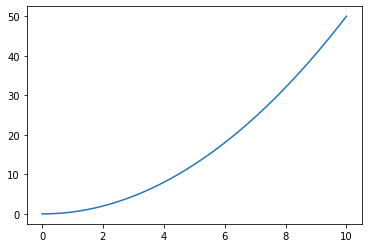

In [7]:
def diff(y,x):
    return np.array(x)
x = np.linspace(0,10,100) #对应x的取值
y = odeint(diff,0,x)  #设初值为0，此时y为一个数组，元素为不同的x对应的y值
#也可以是 y = odeint(lambda y,x:x,0,x)
plt.plot(x,y[:,0]) #y数组（矩阵）的第一列
plt.show()

洛伦兹方程

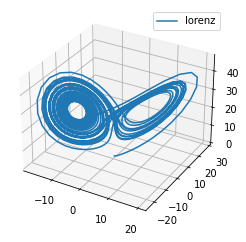

In [9]:
fig = plt.figure()
ax = fig.gca(projection = '3d')

def lorenz(w,t,p,r,b):
    #位置矢量w，三个参数p,r,b
    x,y,z = w.tolist()
    #分别计算dx/dt ,dy/dt,  dz/dt
    return p * (y-x),x*(r-z)-y,x*y-b*z
t = np.arange(0,30,0.02)
initial_val = (0.0,1.00,0.0)

track = odeint(lorenz,initial_val,t,args=(10.0,28.0,3.0))
x,y,z = track[:,0],track[:,1],track[:,2]
ax.plot(x,y,z,label='lorenz')
ax.legend()



插值求解

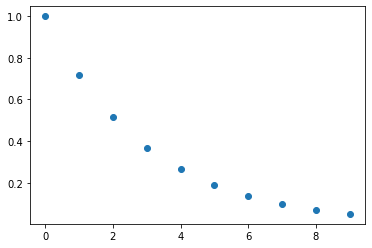

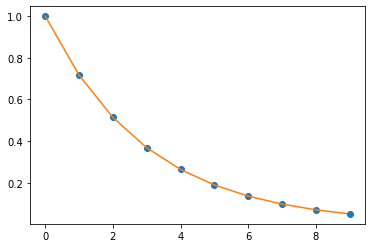

In [17]:
x = np.arange(0,10)
y = np.exp(-x/3.0)
plt.plot(x,y,'o')
plt.show()

f = interpolate.interp1d(x,y)  #返回的是函数
xnew = np.arange(0,9,0.1)
ynew = f(xnew)
plt.plot(x,y,'o',xnew,ynew,'-')
plt.show()

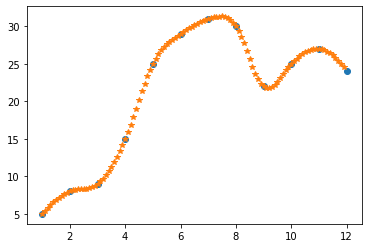

In [19]:
hours = np.arange(1,13)
temperature = [5,8,9,15,25,29,31,30,22,25,27,24]
f = interpolate.interp1d(hours,temperature,kind='quadratic')  #cibic
new_time = np.arange(1,12,0.1)
estimate_temperature = f(new_time)
plt.plot(hours,temperature,'o',new_time,estimate_temperature,'*')
plt.show()


In [5]:
didu = np.array([10,20,40,80,160,320,640,1280])
repeat_f = np.array([4,3,10,10,11,15,14,2])
data = didu.repeat(repeat_f)
print(data)
print(data.mean())
print(stats.gmean(data)) #求几何平均
print(stats.iqr(data)) #求四分位值
print(stats.variation(data)) #求变异系数
print(stats.skew(data))  #偏度
print(stats.kurtosis(data)) #峰度

[  10   10   10   10   20   20   20   40   40   40   40   40   40   40
   40   40   40   80   80   80   80   80   80   80   80   80   80  160
  160  160  160  160  160  160  160  160  160  160  320  320  320  320
  320  320  320  320  320  320  320  320  320  320  320  640  640  640
  640  640  640  640  640  640  640  640  640  640  640 1280 1280]
280.8695652173913
150.64109410382258
240.0
1.0021925756501993
1.4758210321910645
2.3411133773829924


In [9]:
#假设一群学生的身高服从均值为167.7 标准差为5.3的正太分布。 然后在这个群体中抽取样本，

g,n,u,s,a = 100,10,167.7,5.3,0.05
records = []
for i in range(g):
    data = stats.norm.rvs(loc=167.7,scale=5.3,size=n)
#     print(data)
    #每次样本的均值和标准差：
    mean ,xsem = data.mean(),stats.sem(data)
    records.append([mean - stats.t.isf(a/2,n-1)*xsem,mean+stats.t.isf(a/2,n-1)*xsem])
    
count= 0
for i in range(g):
    if records[i][0] < u < records[i][1]:
        count+=1
print("概率为：",count/g)


概率为： 0.95


k= 0.370707071452518 b= -0.30269372618947354


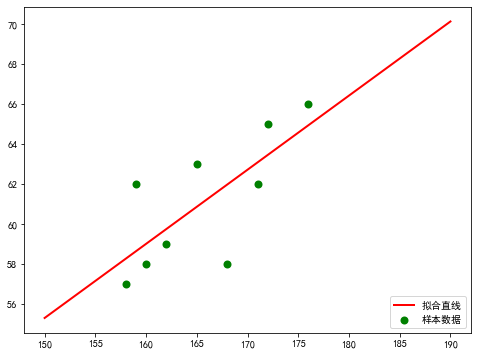

In [16]:
#样本数据
xi = np.array([168,165,158,172,159,176,160,162,171])
yi = np.array([58,63,57,65,62,66,58,59,62])

#需要拟合的函数func ：指定函数的形状， k= 0.42116973935  b = -8.28830260655
def func(p,x):
    k,b=p
    return k*x + b

def error(p,x,y):
    return func(p,x) - y

p0 = [1,20] #初始化K 和b的值，会逐步迭代
para = leastsq(error,p0,args = (xi,yi))
k,b = para[0]
print("k=",k,"b=",b)

plt.figure(figsize=(8,6))
plt.scatter(xi,yi,color="green",label="样本数据",linewidth=2)
# matplotlib.rcParams['font.sans-serif'] = ['SimHei'] #解决中文乱码的问题
plt.rcParams['font.sans-serif']='SimHei'   #显示中文不是乱码
plt.rcParams['axes.unicode_minus']=False   #负号不要解析

#画拟合线
x = np.linspace(150,190,100)
y = k*x + b
plt.plot(x,y,color="red",label="拟合直线",linewidth=2)
plt.legend(loc="lower right")
plt.show()



Optimization terminated successfully.
         Current function value: 0.000002
         Iterations: 35
         Function evaluations: 68
[3.00021471 1.99974856] 1.7007332966814985e-06
[0.         0.75       0.125      1.3125     1.3125     2.8203125
 2.8203125  2.90820312 2.90820312 2.90820312 3.14611816 3.14611816
 2.8629303  3.10084534 3.06400299 2.97267723 2.97267723 2.97267723
 3.01503241 3.00664875 2.99175891 2.99175891 3.00304363 3.00225969
 3.00225969 3.00225969 2.9982729  2.9982729  2.99930506 3.00052434
 3.00052434 3.00052434 2.99975625 3.0000539  3.00021471]
[0.         0.75       1.875      2.9375     2.9375     3.0234375
 3.0234375  2.36523438 2.36523438 2.36523438 2.0057373  2.0057373
 2.17094421 1.81144714 1.99846649 2.03795052 2.03795052 2.03795052
 1.9554795  2.01791659 2.01232428 2.01232428 2.00836436 1.99782214
 1.99782214 1.99782214 2.00260156 2.00260156 1.99945053 1.99942409
 1.99942409 1.99942409 2.00061399 1.99953206 1.99974856]


C:\Users\kim\.virtualenvs\ipython-T2nmkoIa\lib\site-packages\ipykernel_launcher.py:23: MatplotlibDeprecationWarning:

shading='flat' when X and Y have the same dimensions as C is deprecated since 3.3.  Either specify the corners of the quadrilaterals with X and Y, or pass shading='auto', 'nearest' or 'gouraud', or set rcParams['pcolor.shading'].  This will become an error two minor releases later.



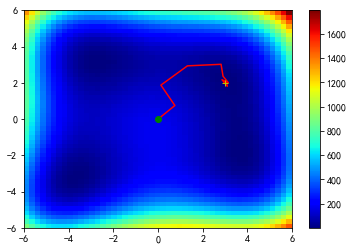

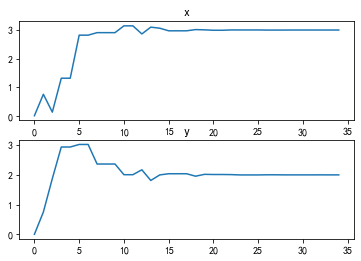

In [33]:
#求解最小值：fmin()
def cost_func(x):
    return (x[0] **2 + x[1] - 11)**2+(x[0]+x[1]**2-7)**2
x_center = np.array([0,0])
step=0.5
x0 = np.vstack((x_center,x_center+np.diag((step,step))))
# print(x0)
xtol,ftol = 1e-3,1e-3
xopt,fopt,iter,funcalls,warnflags,allvecs = fmin(cost_func,x_center,initial_simplex=x0,xtol=xtol,ftol=ftol,disp=1,retall=1,full_output=1)
print(xopt,fopt)

n=50
x = np.linspace(-6,6,n)
y = np.linspace(-6,6,n)
z = np.zeros((n,n))

for i,a  in enumerate(x):
    for j,b in enumerate(y):
        z[i,j] = cost_func([a,b])

xx,yy = np.meshgrid(x,y)
fig,ax = plt.subplots()
c = ax.pcolormesh(xx,yy,z.T,cmap="jet")
fig.colorbar(c,ax=ax)

t = np.asarray(allvecs)
x_,y_ = t[:,0],t[:,1]
# print(t)
print(x_)
print(y_)

ax.plot(x_,y_,'r',x_[0],y_[0],'go',x_[-1],y_[-1],'y+')

fig2 = plt.figure()
ax1 = plt.subplot(211)
ax2 = plt.subplot(212)
ax1.plot(x_)
ax1.set_title('x')
ax2.plot(y_)
ax2.set_title('y')
plt.show()


In [41]:
def f(x):
    return (x-3) **2
res = minimize(f,5)


In [42]:
res

      fun: 3.566296139491455e-16
 hess_inv: array([[0.5]])
      jac: array([-2.28681181e-08])
  message: 'Optimization terminated successfully.'
     nfev: 6
      nit: 2
     njev: 3
   status: 0
  success: True
        x: array([2.99999998])

In [37]:
f = lambda x: (x[0] - 1) **2  + (x[1] - 2.5)**2
cons = ({'type':'ineq','fun':lambda x:x[0] - 2 * x[1] + 2},
        {'type':'ineq','fun':lambda x:-x[0] - 2 * x[1] + 6},
        {'type':'ineq','fun':lambda x:-x[0] + 2 * x[1] + 2})
bnds = ((0,None),(0,None))
res = minimize(f,(2,0),bounds=bnds,constraints=cons)

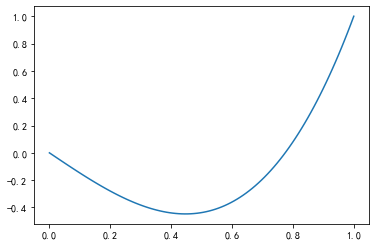

In [55]:
#legendre多项式、贝塞尔函数：
x = np.linspace(0,1,100)
plt.plot(x,legendre(3)(x))
plt.show()



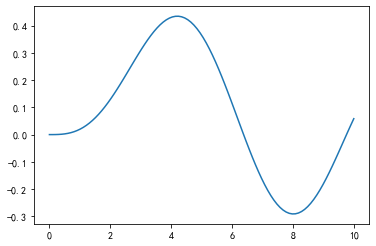

In [56]:
#legendre多项式、贝塞尔函数：
x = np.linspace(0,10,100)
plt.plot(x,jv(3,x))
plt.show()

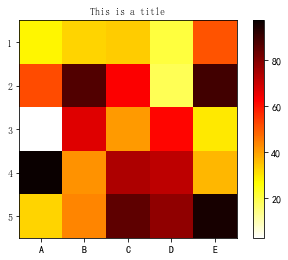